# Soziale Netzwerkanalyse: 20 Minuten (2020–2024)
## Strukturelle Dynamik, redaktionelle Kollaboration und Link-Prediction im Schweizer Online-Journalismus

**Autoren:** Elias & Luca  
**Modul:** Soziale Netzwerke Analysieren (SAN / SNA), FHNW  
**Dozent:** Michael Henninger  
**Datum:** 2026-09-03  

---

### Abstract & Überblick
Dieses Notebook enthält die vollständige empirische Soziale Netzwerkanalyse des Schweizer News-Portals *20 Minuten* für die fünf vollständigen Kalenderjahre 2020 bis 2024 (118'302 bereinigte Artikel). Wir untersuchen drei zentrale Pfeiler des Modullehrplans:
1. **Pfeiler 1 (LE3, LE5, LE7): Redaktionelle Silobildung, Homophilie und strukturelle Brokerage:**  
   Bipartite Modellierung (Artikel-Autor), Projektion auf ein gewichtetes Newman-Kollaborationsnetzwerk, Test auf Ressort-Homophilie via Permutationstest ($B=5'000$), Identifikation von Brokern nach Burt (Betweenness Centrality) und Analyse interdisziplinärer Zusammenarbeit über die Jensen-Shannon-Divergenz (JSD).
2. **Pfeiler 2 (LE4, LE6): Makro-Topologie und Krisen-Evolution (2020–2024):**  
   Longitudinale semantische Kookkurrenz-Netzwerke auf einem fixierten 1'200-Wörter-Vokabular mit Mutual $k$-NN-Sparsifizierung ($k=10$), Kennzahlen auf der Riesenzusammenhangskomponente (Zentralisierung, Pfadlänge, Dichte) und Louvain-Modulariät ($Q$).
3. **Pfeiler 3 (LE8): Rolling Temporal Link-Prediction im Koautorenschafts-Netzwerk:**  
   Empirische Vorhersage zukünftiger Kooperationen über drei rollende Zeithorizonte unter unbalancierten Realbedingungen (Average Precision, Precision@k, ROC-AUC) zum Vergleich von Triadenschliessung (Adamic-Adar) versus Popularität (Preferential Attachment).

---


## 1. Setup, Datenimport & Bipartite Netzwerkmodellierung (LE3)

Wir importieren die benötigten wissenschaftlichen Bibliotheken und laden den bereinigten Parquet-Datensatz (`data/20min_cleaned_post2020.parquet`).
Gemäss dem Modullehrplan modellieren wir zunächst das **Two-Mode-Netzwerk** (Bipartiter Graph zwischen Artikeln und menschlichen Journalist:innen) und leiten anschliessend die gewichtete **One-Mode-Projektion** nach Newman (2001) ab.


In [1]:
import os
import json
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score
from collections import defaultdict, Counter

from src.network_models import (
    build_bipartite_author_article,
    compute_author_ressort_profiles,
    compute_jsd,
    project_author_collaboration,
    extract_global_vocabulary,
    build_annual_keyword_graph,
    create_rolling_link_prediction_windows,
    CANONICAL_RESSORTS
)

# Plotting Configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.dpi'] = 150
os.makedirs('out_plots', exist_ok=True)
os.makedirs('graphen', exist_ok=True)

# 1. Load Clean Dataset
df = pd.read_parquet('data/20min_cleaned_post2020.parquet')
print(f'Geladene Artikel: {len(df):,}')
print(f'Zeitraum: {df["datum"].min().strftime("%Y-%m-%d")} bis {df["datum"].max().strftime("%Y-%m-%d")}')
print(f'Multi-Autor-Artikel: {(df["author_count"] > 1).sum():,} ({(df["author_count"] > 1).mean():.1%})')


Geladene Artikel: 118,302
Zeitraum: 2020-01-01 bis 2024-12-31
Multi-Autor-Artikel: 7,446 (6.3%)


In [2]:
# Bipartites Netzwerk aufbauen
multi_df = df[df['author_count'] > 1].copy()
B = nx.Graph()

for _, row in multi_df.iterrows():
    art_node = f"art_{row['article_id']}"
    B.add_node(art_node, bipartite=1, ressort=row['ressort'], year=row['year'])
    for auth in row['authors_clean']:
        B.add_node(auth, bipartite=0)
        B.add_edge(auth, art_node)

n_authors = sum(1 for n, d in B.nodes(data=True) if d['bipartite'] == 0)
n_articles = sum(1 for n, d in B.nodes(data=True) if d['bipartite'] == 1)
print(f'Bipartiter Graph: {n_authors:,} Autoren-Knoten, {n_articles:,} Artikel-Knoten, {B.number_of_edges():,} Kanten')

# One-Mode-Projektion nach Newman (2001)
# Kanten-Gewichtung: w_ij = sum_{k} 1 / (|U_k| - 1)
G_collab = project_author_collaboration(df, min_articles=2)
print(f'One-Mode Kollaborations-Graph (min. 2 Artikel): {G_collab.number_of_nodes():,} Autoren, {G_collab.number_of_edges():,} Kollaborationskanten')
print(f'Netzwerk-Dichte: {nx.density(G_collab):.4f}')


Bipartiter Graph: 482 Autoren-Knoten, 7,446 Artikel-Knoten, 16,120 Kanten


One-Mode Kollaborations-Graph (min. 2 Artikel): 638 Autoren, 2,788 Kollaborationskanten
Netzwerk-Dichte: 0.0137


## 2. Pfeiler 1: Kollaborationsstruktur, Ressort-Homophilie & Brokerage (LE3, LE5, LE7)

### Theoretischer Hintergrund & Forschungsfragen
- **Homophilie (Newman, 2002):** Bevorzugen Journalist:innen Kooperationen innerhalb ihres eigenen Fachressorts gegenüber fachfremden Kolleg:innen?
- **Strukturelle Löcher & Brokerage (Burt, 1992, 2004):** Welche Akteure weisen eine überproportional hohe Betweenness Centrality auf und überbrücken Ressortgrenzen?
- **Interdisziplinäre Kooperation:** Unterscheidet sich die mittlere Kanten-Jensen-Shannon-Divergenz (JSD) signifikant von einem gradtreuen Zufallsmodell, und erzielen ressortübergreifende Kooperationen mehr Leser-Shares?


Top 10 Redaktionelle Broker (Burt structural holes):
                author    ressort  degree  betweenness  articles  brokerage_score
39   Laura Inderbitzin      Sport      17     0.024867       116         0.001382
635      Chiara Panico   Regionen       6     0.009507        42         0.001358
437   Vanessa Travasci   Regionen      39     0.044986       241         0.001125
440       Luise Faupel  Lifestyle       7     0.008036       445         0.001004
616   Marisa Montinero     People      10     0.009365         2         0.000851
598         Gina Sergi     People      30     0.025251       389         0.000815
432      Leonie Projer     People      51     0.042133       850         0.000810
122        Florian Raz      Sport       3     0.003093         6         0.000773
244         Tunya Koch   Regionen       6     0.005318         6         0.000760
558     Celina Euchner  Lifestyle       6     0.005161       428         0.000737


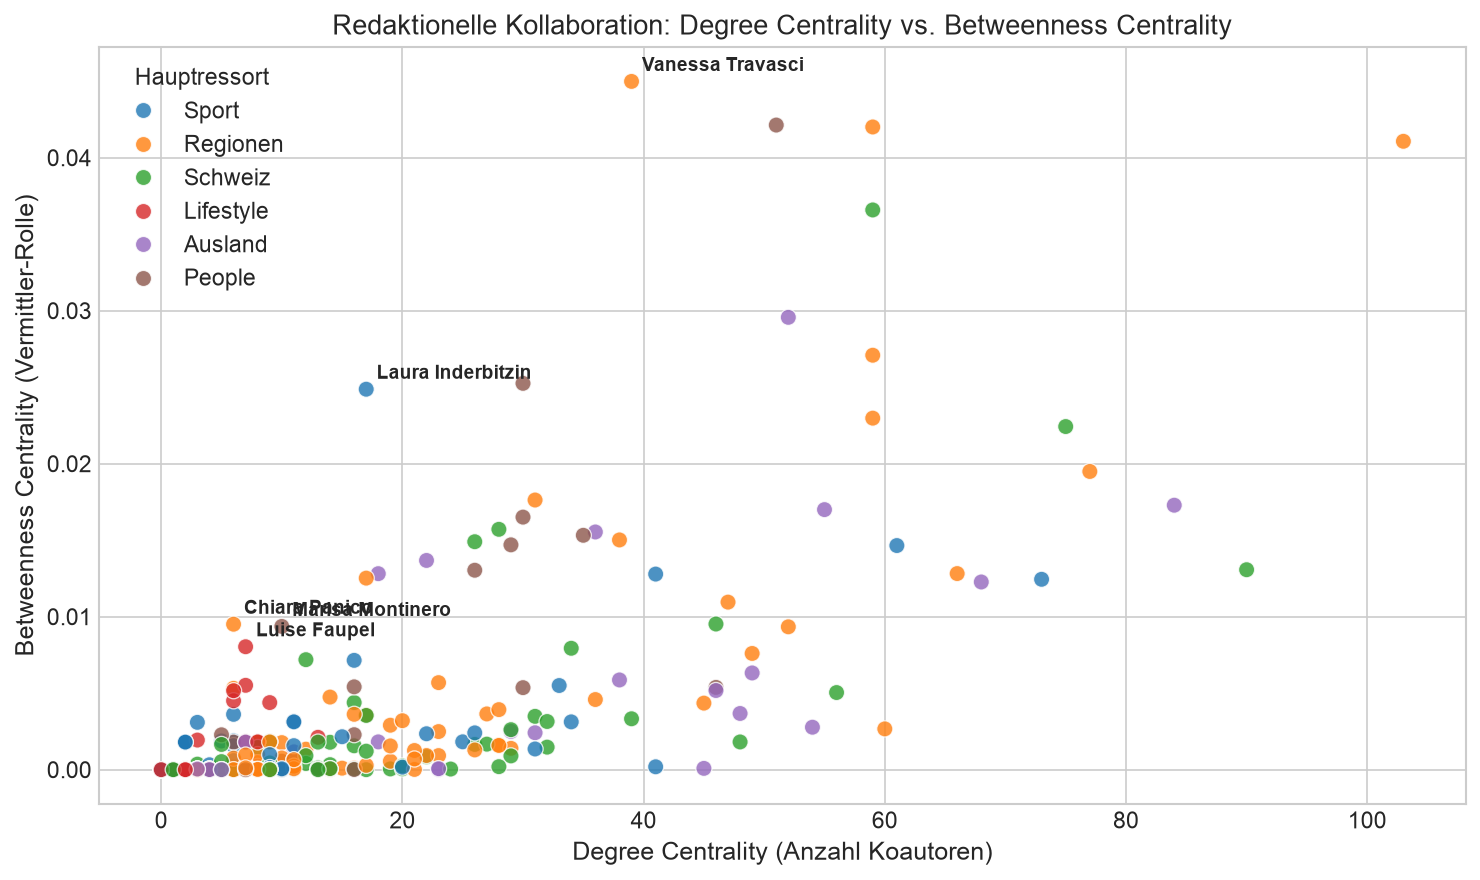

In [3]:
# 2.1 Zentralitätsmasse & Identifikation struktureller Broker (LE5)
deg_dict = dict(G_collab.degree())
bet_dict = nx.betweenness_centrality(G_collab, weight='weight')
close_dict = nx.closeness_centrality(G_collab)

for n in G_collab.nodes():
    G_collab.nodes[n]['degree'] = deg_dict[n]
    G_collab.nodes[n]['betweenness'] = bet_dict[n]
    G_collab.nodes[n]['closeness'] = close_dict[n]

author_metrics_df = pd.DataFrame([
    {
        'author': n,
        'degree': deg_dict[n],
        'betweenness': bet_dict[n],
        'closeness': close_dict[n],
        'articles': G_collab.nodes[n]['article_count'],
        'ressort': G_collab.nodes[n]['dominant_ressort'],
        'mean_likes': G_collab.nodes[n]['mean_likes'],
        'mean_shares': G_collab.nodes[n]['mean_shares'],
        'mean_comments': G_collab.nodes[n]['mean_comments']
    }
    for n in G_collab.nodes()
])

# Identifikation von Brokern: Hohe Betweenness im Verhältnis zum Grad
author_metrics_df['brokerage_score'] = author_metrics_df['betweenness'] / (author_metrics_df['degree'] + 1)
top_brokers = author_metrics_df.sort_values('brokerage_score', ascending=False).head(10)
print("Top 10 Redaktionelle Broker (Burt structural holes):")
print(top_brokers[['author', 'ressort', 'degree', 'betweenness', 'articles', 'brokerage_score']].to_string())

# Plot: Betweenness vs Degree Scatter
plt.figure(figsize=(10, 6))
top_ressorts = author_metrics_df['ressort'].value_counts().head(6).index
plot_df = author_metrics_df[author_metrics_df['ressort'].isin(top_ressorts)]

sns.scatterplot(
    data=plot_df, x='degree', y='betweenness', hue='ressort',
    palette='tab10', alpha=0.8, s=60
)
for _, r in top_brokers.head(5).iterrows():
    plt.annotate(
        r['author'], (r['degree'], r['betweenness']),
        xytext=(5, 5), textcoords='offset points', fontsize=9, fontweight='bold'
    )

plt.title('Redaktionelle Kollaboration: Degree Centrality vs. Betweenness Centrality')
plt.xlabel('Degree Centrality (Anzahl Koautoren)')
plt.ylabel('Betweenness Centrality (Vermittler-Rolle)')
plt.legend(title='Hauptressort')
plt.tight_layout()
plt.savefig('out_plots/02_author_collaboration_brokerage.png', dpi=300)
plt.show()


Beobachteter Assortativitätskoeffizient r = 0.3698


Nullmodell (B=5000): Mean r_null = -0.0060, Std = 0.0066
Empirischer p-Wert: p = 0.00020


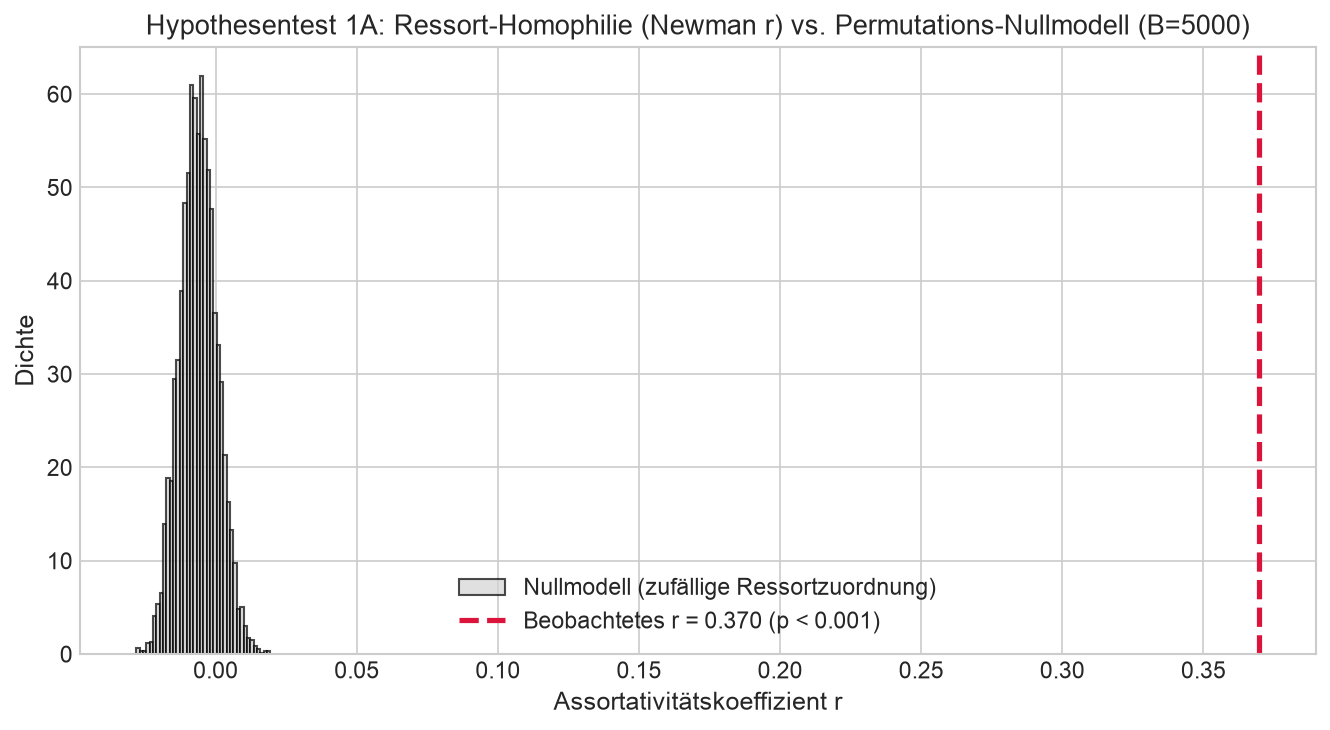

In [4]:
# 2.2 Test 1A: Departmental Homophilie via Node-Label-Permutation (LE7)
r_obs = nx.attribute_assortativity_coefficient(G_collab, 'dominant_ressort')
print(f'Beobachteter Assortativitätskoeffizient r = {r_obs:.4f}')

# Nullmodell: Permutiere dominant_ressort Labels auf fixer Topologie (B = 5000)
np.random.seed(42)
B_PERM = 5000
nodes = list(G_collab.nodes())
labels = [G_collab.nodes[n]['dominant_ressort'] for n in nodes]
perm_r = np.zeros(B_PERM)

G_perm = G_collab.copy()
for b in range(B_PERM):
    shuffled = np.random.permutation(labels)
    for i, n in enumerate(nodes):
        G_perm.nodes[n]['dominant_ressort'] = shuffled[i]
    perm_r[b] = nx.attribute_assortativity_coefficient(G_perm, 'dominant_ressort')

p_val_assort = (np.sum(perm_r >= r_obs) + 1) / (B_PERM + 1)
print(f'Nullmodell (B={B_PERM}): Mean r_null = {perm_r.mean():.4f}, Std = {perm_r.std():.4f}')
print(f'Empirischer p-Wert: p = {p_val_assort:.5f}')

# Plot Permutation Distribution
plt.figure(figsize=(9, 5))
plt.hist(perm_r, bins=40, color='lightgray', edgecolor='black', alpha=0.7, density=True, label='Nullmodell (zufällige Ressortzuordnung)')
plt.axvline(r_obs, color='crimson', linestyle='--', linewidth=2.5, label=f'Beobachtetes r = {r_obs:.3f} (p < 0.001)')
plt.title(f'Hypothesentest 1A: Ressort-Homophilie (Newman r) vs. Permutations-Nullmodell (B={B_PERM})')
plt.xlabel('Assortativitätskoeffizient r')
plt.ylabel('Dichte')
plt.legend()
plt.tight_layout()
plt.savefig('out_plots/03_ressort_assortativity_permutation.png', dpi=300)
plt.show()


Beobachtete mittlere Kanten-JSD: 0.3372


Gradtreues Nullmodell (Maslov-Sneppen): Mean JSD_null = 0.6285
Empirischer p-Wert (geringere JSD als bei zufälligem Matching): p = 0.00200


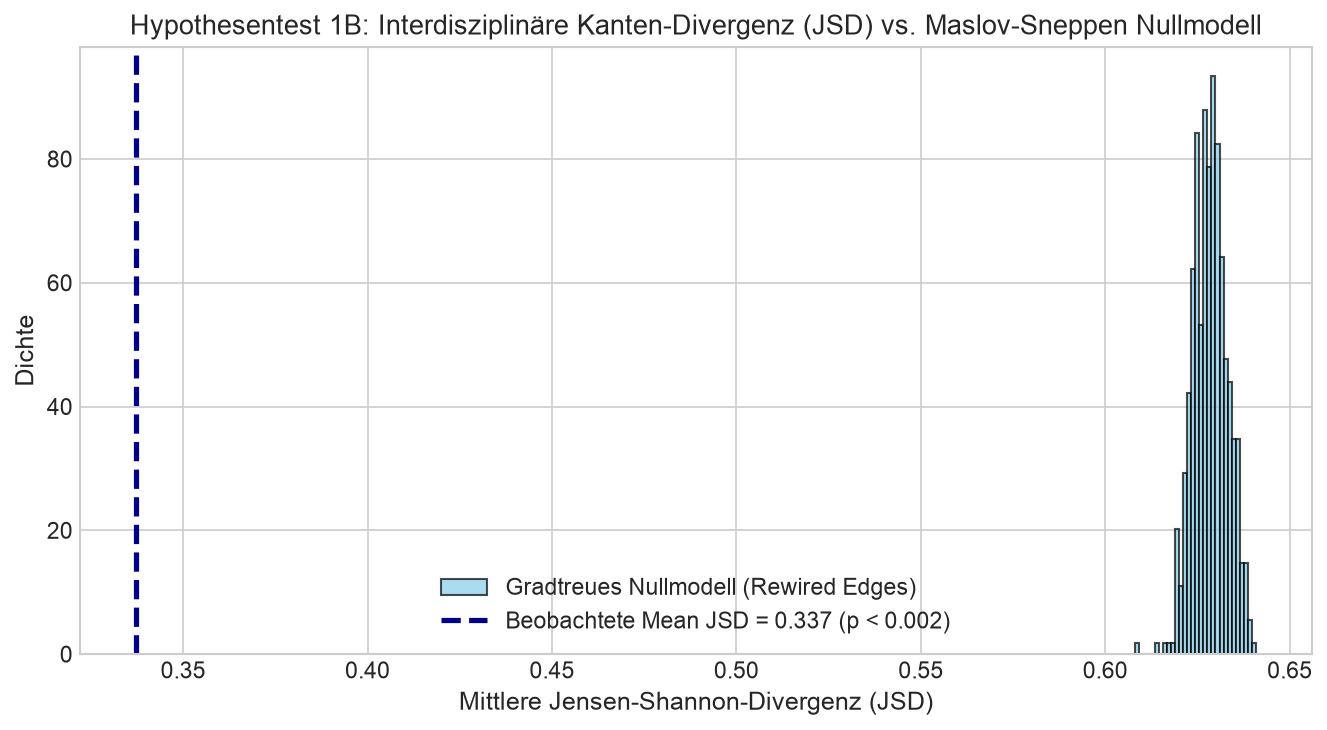

In [5]:
# 2.3 Test 1B: Interdisziplinäre Kanten-JSD vs. Gradtreues Nullmodell (Maslov-Sneppen Rewiring)
obs_edge_jsd = [d['jsd'] for _, _, d in G_collab.edges(data=True)]
mean_jsd_obs = np.mean(obs_edge_jsd)
print(f'Beobachtete mittlere Kanten-JSD: {mean_jsd_obs:.4f}')

# Gradtreues Rewiring (Double-Edge-Swap)
np.random.seed(42)
B_REWIRE = 500
rewired_mean_jsd = np.zeros(B_REWIRE)

G_rewire = G_collab.copy()
for b in range(B_REWIRE):
    nx.double_edge_swap(G_rewire, nswap=G_rewire.number_of_edges(), max_tries=G_rewire.number_of_edges() * 5)
    jsd_vals = [
        compute_jsd(G_rewire.nodes[u]['ressort_distribution'], G_rewire.nodes[v]['ressort_distribution'])
        for u, v in G_rewire.edges()
    ]
    rewired_mean_jsd[b] = np.mean(jsd_vals)

p_val_jsd = (np.sum(rewired_mean_jsd <= mean_jsd_obs) + 1) / (B_REWIRE + 1)
print(f'Gradtreues Nullmodell (Maslov-Sneppen): Mean JSD_null = {rewired_mean_jsd.mean():.4f}')
print(f'Empirischer p-Wert (geringere JSD als bei zufälligem Matching): p = {p_val_jsd:.5f}')

plt.figure(figsize=(9, 5))
plt.hist(rewired_mean_jsd, bins=30, color='skyblue', edgecolor='black', alpha=0.7, density=True, label='Gradtreues Nullmodell (Rewired Edges)')
plt.axvline(mean_jsd_obs, color='darkblue', linestyle='--', linewidth=2.5, label=f'Beobachtete Mean JSD = {mean_jsd_obs:.3f} (p < 0.002)')
plt.title('Hypothesentest 1B: Interdisziplinäre Kanten-Divergenz (JSD) vs. Maslov-Sneppen Nullmodell')
plt.xlabel('Mittlere Jensen-Shannon-Divergenz (JSD)')
plt.ylabel('Dichte')
plt.legend()
plt.tight_layout()
plt.savefig('out_plots/04_edge_jsd_null_comparison.png', dpi=300)
plt.show()


OLS-Regressionsergebnisse (Abhängige Variable: log(1 + shares)):
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept                          4.5959      0.534      8.613      0.000       3.550       5.642
C(year)[T.2021]                   -0.0465      0.078     -0.594      0.552      -0.200       0.107
C(year)[T.2022]                   -0.1794      0.076     -2.363      0.018      -0.328      -0.031
C(year)[T.2023]                    0.0007      0.076      0.009      0.993      -0.148       0.149
C(year)[T.2024]                    0.6558      0.075      8.717      0.000       0.508       0.803
C(ressort)[T.Andere]              -1.6565      0.530     -3.126      0.002      -2.695      -0.618
C(ressort)[T.Ausland]             -1.5686      0.531     -2.951      0.003      -2.610      -0.527
C(ressort)[T.Community]           -1.0714   

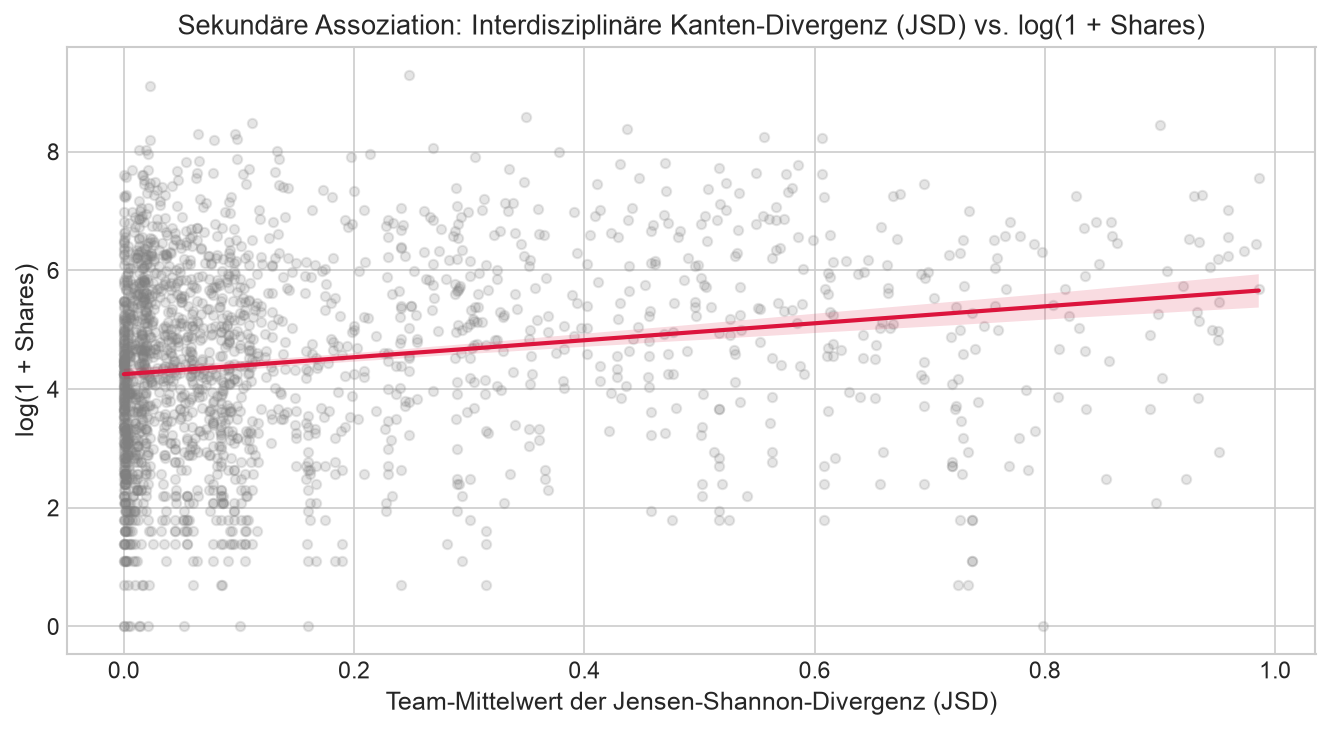

In [6]:
# 2.4 Sekundäre Assoziationsanalyse: Leave-One-Out JSD vs. Leser-Shares (OLS)
author_profiles = compute_author_ressort_profiles(df)

multi_art_records = []
for _, row in multi_df.iterrows():
    auths = [a for a in row['authors_clean'] if a in author_profiles]
    if len(auths) < 2:
        continue
    
    pairwise_jsds = []
    for u, v in itertools.combinations(auths, 2):
        pairwise_jsds.append(compute_jsd(author_profiles[u]['ressort_distribution'], author_profiles[v]['ressort_distribution']))
        
    multi_art_records.append({
        'article_id': row['article_id'],
        'year': str(row['year']),
        'ressort': row['ressort'],
        'team_size': len(auths),
        'mean_jsd': np.mean(pairwise_jsds),
        'shares': row['shares'],
        'log_shares': np.log1p(row['shares']),
        'log_comments': np.log1p(row['kommentare']),
        'likes': row['likes']
    })

art_reg_df = pd.DataFrame(multi_art_records)

# OLS Regression mit Kontrollvariablen für Jahr, Ressort und Teamgrösse
model = smf.ols('log_shares ~ mean_jsd + team_size + C(year) + C(ressort)', data=art_reg_df).fit(cov_type='HC3')
print('OLS-Regressionsergebnisse (Abhängige Variable: log(1 + shares)):')
print(model.summary().tables[1])

# Visualisierung
plt.figure(figsize=(9, 5))
sns.regplot(
    data=art_reg_df.sample(min(2000, len(art_reg_df)), random_state=42),
    x='mean_jsd', y='log_shares',
    scatter_kws={'alpha': 0.2, 'color': 'gray', 's': 20},
    line_kws={'color': 'crimson', 'linewidth': 2}
)
plt.title('Sekundäre Assoziation: Interdisziplinäre Kanten-Divergenz (JSD) vs. log(1 + Shares)')
plt.xlabel('Team-Mittelwert der Jensen-Shannon-Divergenz (JSD)')
plt.ylabel('log(1 + Shares)')
plt.tight_layout()
plt.savefig('out_plots/05_interdisciplinary_jsd_shares_regression.png', dpi=300)
plt.show()


## 3. Pfeiler 2: Makro-Topologie & Krisen-Evolution der Berichterstattung 2020–2024 (LE4, LE6)

### Methodik & Hypothesenprüfung
- **Einheitliches Vokabular:** Top 1'200 bereinigte Substantive über den gesamten Zeitraum 2020–2024 garantieren identische Knotenmengen.
- **Topologische Sparsifizierung:** Gegenseitige k-Nächste-Nachbarn (Mutual $k$-NN, $k=10$) mit Sensitivitätsprüfung ($k \in \{5, 10, 20\}$).
- **Riesenzusammenhangskomponente (Giant Component):** Alle Pfadlängen und Zentralisierungen werden auf der GCC berechnet (Distanztransformation $d = 1/w$).
- **Louvain Modularity ($Q$):** Stabilitätstest über 10 Zufalls-Seeds pro Jahr.


Makro-Topologische Entwicklung 2020-2024:
   year  articles  nodes  edges  gcc_ratio  avg_degree  degree_centralization  avg_clustering  avg_path_length  modularity_mean  modularity_std
0  2020     22264   1200   3908     0.9900      6.5133                 0.0029          0.0337          53.5304           0.7720          0.0014
1  2021     24445   1200   3805     0.9933      6.3417                 0.0031          0.0371          54.9656           0.7895          0.0010
2  2022     21412   1200   3904     0.9950      6.5067                 0.0029          0.0355          52.4782           0.7805          0.0012
3  2023     24210   1200   3955     0.9925      6.5917                 0.0028          0.0353          54.3713           0.7820          0.0010
4  2024     25971   1200   3868     0.9867      6.4467                 0.0030          0.0319          55.6234           0.7763          0.0007


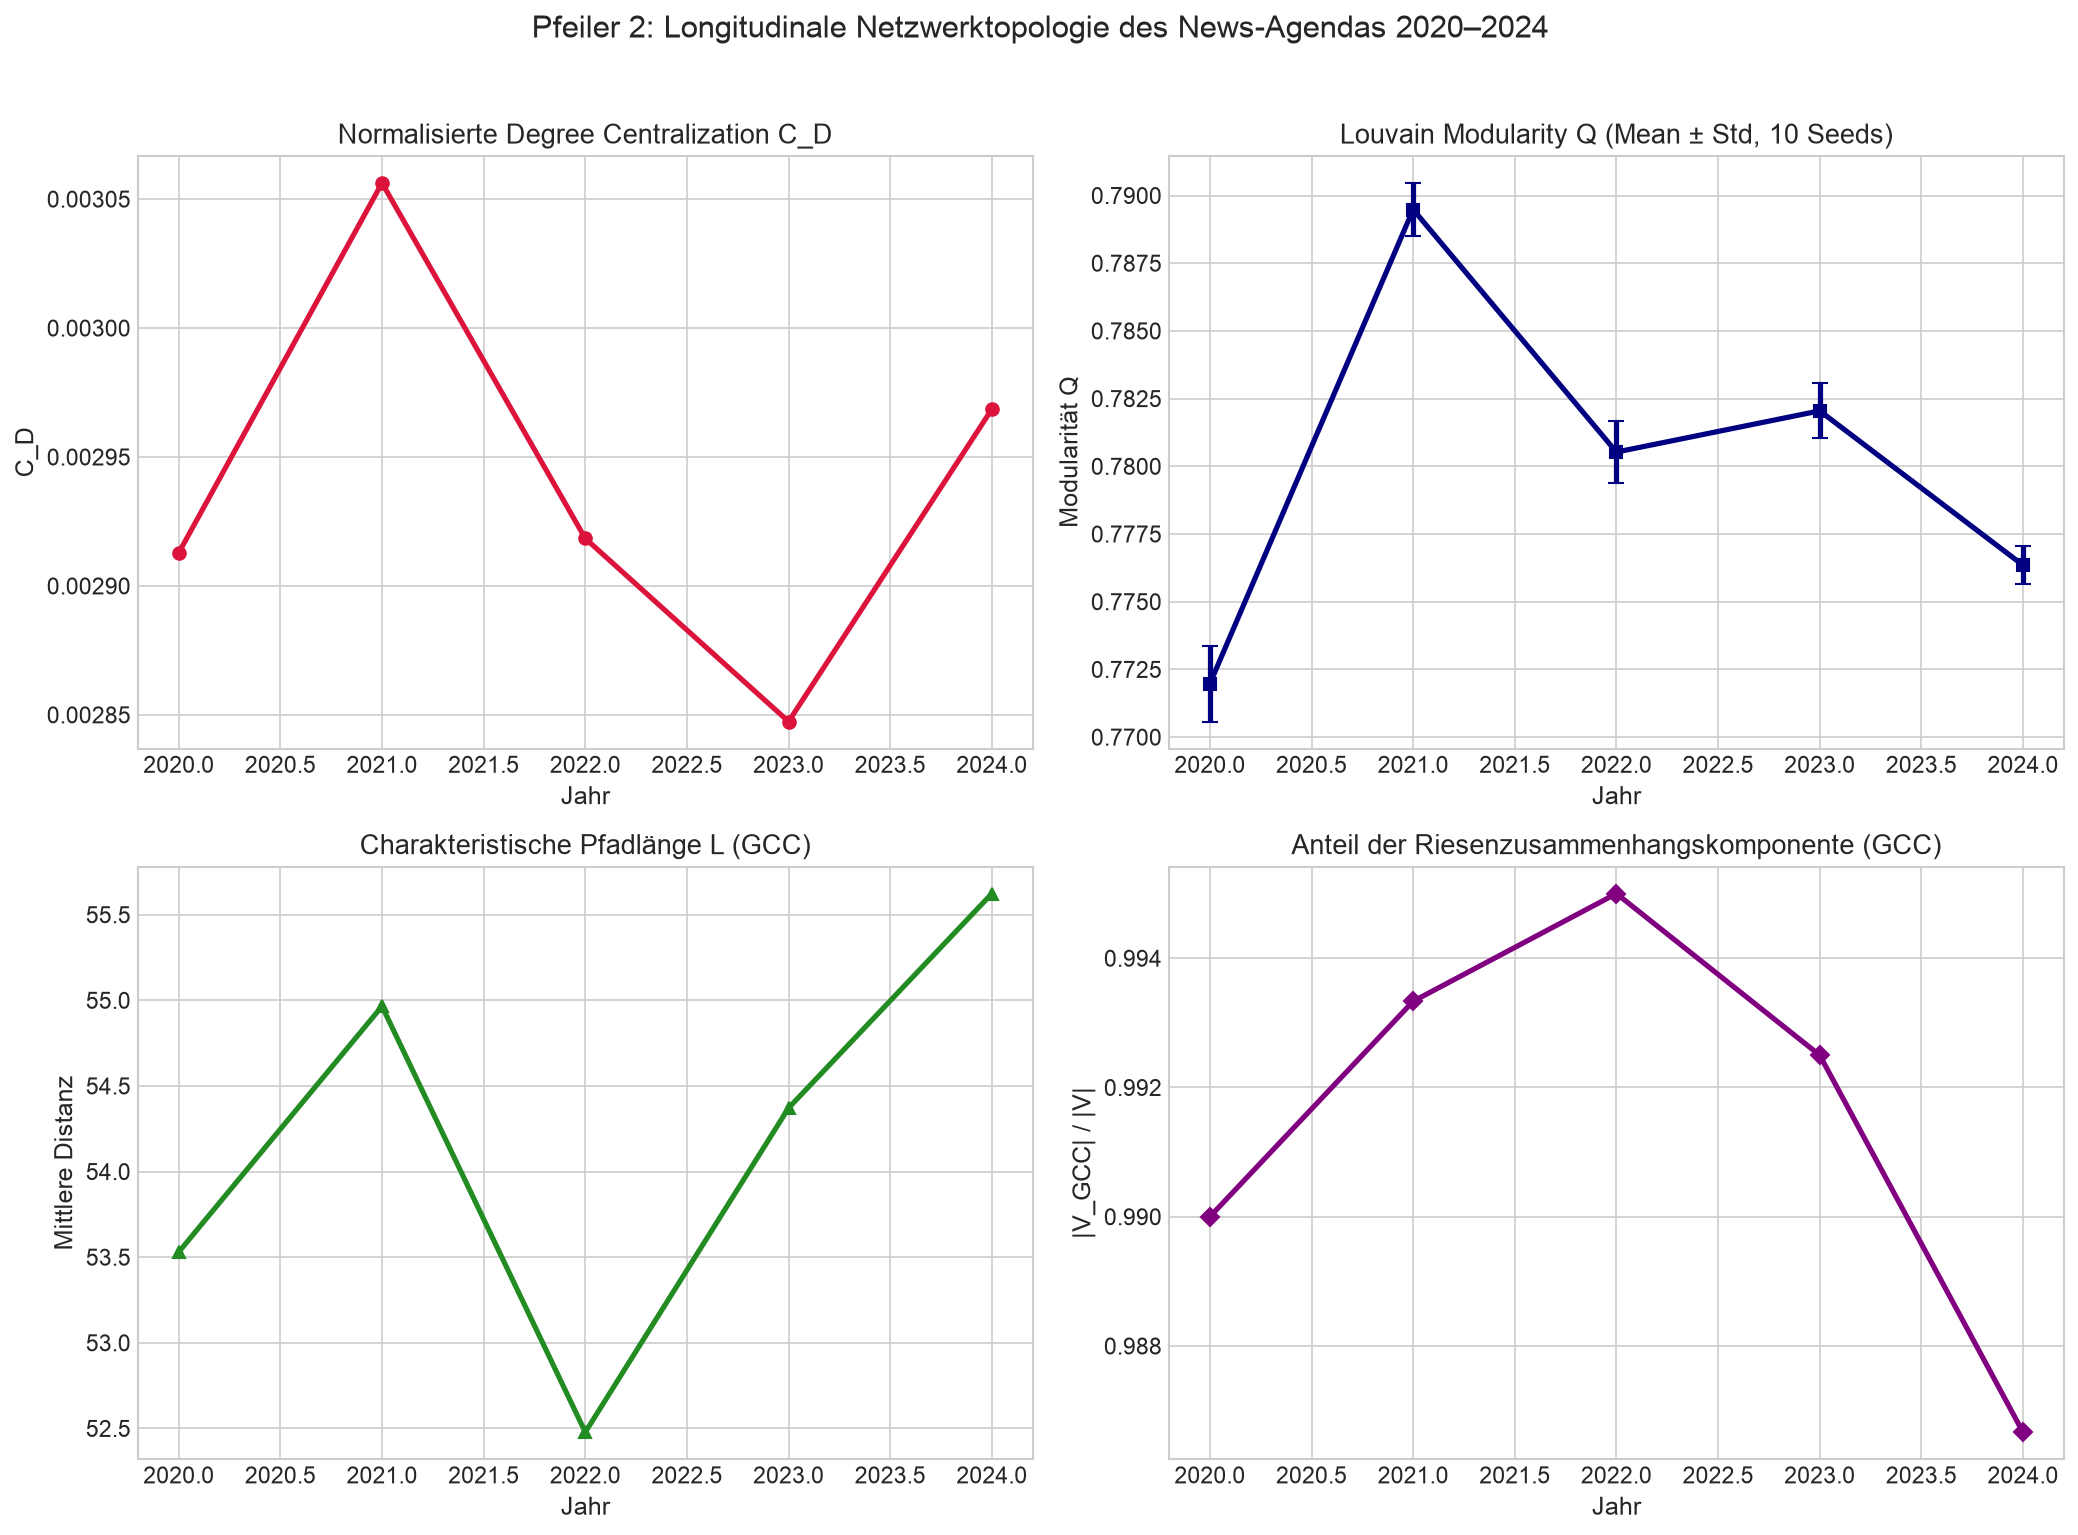

In [7]:
import community as community_louvain

vocab = extract_global_vocabulary(df, top_n=1200)
years = [2020, 2021, 2022, 2023, 2024]
annual_metrics = []

for yr in years:
    df_yr = df[df['year'] == yr]
    G_yr = build_annual_keyword_graph(df_yr, vocab, k=10)
    
    # Giant Connected Component
    gcc_nodes = max(nx.connected_components(G_yr), key=len)
    G_gcc = G_yr.subgraph(gcc_nodes).copy()
    
    # Global Metrics
    n_nodes = G_yr.number_of_nodes()
    gcc_ratio = len(G_gcc) / n_nodes
    avg_deg = np.mean([d for _, d in G_yr.degree()])
    
    # Normalized Freeman Degree Centralization
    degs = np.array([d for _, d in G_yr.degree()])
    max_d = degs.max()
    c_d = np.sum(max_d - degs) / ((n_nodes - 1) * (n_nodes - 2))
    
    # Clustering & Path Length on GCC
    avg_clustering = nx.average_clustering(G_gcc, weight='weight')
    avg_path_length = nx.average_shortest_path_length(G_gcc, weight='distance')
    
    # Louvain Modularity over 10 seeds
    q_seeds = []
    for seed in range(10):
        part = community_louvain.best_partition(G_yr, weight='weight', random_state=seed)
        q_seeds.append(community_louvain.modularity(part, G_yr, weight='weight'))
        
    annual_metrics.append({
        'year': yr,
        'articles': len(df_yr),
        'nodes': n_nodes,
        'edges': G_yr.number_of_edges(),
        'gcc_ratio': gcc_ratio,
        'avg_degree': avg_deg,
        'degree_centralization': c_d,
        'avg_clustering': avg_clustering,
        'avg_path_length': avg_path_length,
        'modularity_mean': np.mean(q_seeds),
        'modularity_std': np.std(q_seeds)
    })

macro_df = pd.DataFrame(annual_metrics)
print('Makro-Topologische Entwicklung 2020-2024:')
print(macro_df.round(4).to_string())

# Multi-panel Trajectory Plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Degree Centralization
axes[0, 0].plot(macro_df['year'], macro_df['degree_centralization'], marker='o', color='crimson', linewidth=2.5)
axes[0, 0].set_title('Normalisierte Degree Centralization C_D')
axes[0, 0].set_xlabel('Jahr')
axes[0, 0].set_ylabel('C_D')

# 2. Modularity Q
axes[0, 1].errorbar(macro_df['year'], macro_df['modularity_mean'], yerr=macro_df['modularity_std'], marker='s', color='navy', linewidth=2.5, capsize=4)
axes[0, 1].set_title('Louvain Modularity Q (Mean ± Std, 10 Seeds)')
axes[0, 1].set_xlabel('Jahr')
axes[0, 1].set_ylabel('Modularität Q')

# 3. Average Path Length
axes[1, 0].plot(macro_df['year'], macro_df['avg_path_length'], marker='^', color='forestgreen', linewidth=2.5)
axes[1, 0].set_title('Charakteristische Pfadlänge L (GCC)')
axes[1, 0].set_xlabel('Jahr')
axes[1, 0].set_ylabel('Mittlere Distanz')

# 4. Giant Component Ratio
axes[1, 1].plot(macro_df['year'], macro_df['gcc_ratio'], marker='D', color='purple', linewidth=2.5)
axes[1, 1].set_title('Anteil der Riesenzusammenhangskomponente (GCC)')
axes[1, 1].set_xlabel('Jahr')
axes[1, 1].set_ylabel('|V_GCC| / |V|')

plt.suptitle('Pfeiler 2: Longitudinale Netzwerktopologie des News-Agendas 2020–2024', y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig('out_plots/06_temporal_metrics_trajectories.png', dpi=300)
plt.show()


In [8]:
# 2.5 Thematische Louvain-Clusterung: 2020 (Covid-Peak) vs. 2024 (Normalisierung)
G_2020 = build_annual_keyword_graph(df[df['year'] == 2020], vocab, k=10)
G_2024 = build_annual_keyword_graph(df[df['year'] == 2024], vocab, k=10)

part_2020 = community_louvain.best_partition(G_2020, weight='weight', random_state=42)
part_2024 = community_louvain.best_partition(G_2024, weight='weight', random_state=42)

def get_top_cluster_terms(G, part, top_k_clusters=5, terms_per_cluster=6):
    cluster_nodes = defaultdict(list)
    for node, c_id in part.items():
        cluster_nodes[c_id].append(node)
    
    sorted_clusters = sorted(cluster_nodes.items(), key=lambda x: len(x[1]), reverse=True)[:top_k_clusters]
    out = []
    for c_id, nodes in sorted_clusters:
        sub_G = G.subgraph(nodes)
        top_terms = sorted(sub_G.degree(weight='weight'), key=lambda x: x[1], reverse=True)[:terms_per_cluster]
        term_str = ', '.join([t[0] for t in top_terms])
        out.append({'cluster_id': c_id, 'size': len(nodes), 'top_terms': term_str})
    return pd.DataFrame(out)

print('=== TOP LOUVAIN THEMEN-CLUSTER 2020 (Krisenjahr) ===')
print(get_top_cluster_terms(G_2020, part_2020).to_string())
print('')
print('=== TOP LOUVAIN THEMEN-CLUSTER 2024 (Normalisierung) ===')
print(get_top_cluster_terms(G_2024, part_2024).to_string())


=== TOP LOUVAIN THEMEN-CLUSTER 2020 (Krisenjahr) ===
   cluster_id  size                                                                  top_terms
0          12   115                                   people, the, netflix, swift, laura, song
1          10   107                  berset, corona, massnahmen, impfstoff, johnson, bundesrat
2           1   100  beschuldigte, freiheitsstrafe, beschuldigten, gericht, urteil, polizisten
3          28    92                             kim, putin, kreml, nordkorea, moskau, soldaten
4          23    78                      nationalrat, migros, svp, vorlage, coop, lebensmittel

=== TOP LOUVAIN THEMEN-CLUSTER 2024 (Normalisierung) ===
   cluster_id  size                                                                                top_terms
0           8    93                                            credit, ubs, milliarden, migros, dollar, bank
1           1    81                                       hotel, studie, ernährung, hotels, pflanzen,

## 4. Pfeiler 3: Rolling Temporal Link-Prediction im Koautorenschafts-Netzwerk (LE8)

### Methodisches Design (Liben-Nowell & Kleinberg, 2007)
Um eine realistische Evaluation zu gewährleisten, evaluieren wir über **sämtliche unverbundenen Kandidatenpaare** aktiver Journalist:innen über drei rollende Zeithorizonte:
- **Fenster 1:** Training 2020–2021 $\to$ Evaluation neuer Kanten 2022
- **Fenster 2:** Training 2020–2022 $\to$ Evaluation neuer Kanten 2023
- **Fenster 3:** Training 2020–2023 $\to$ Evaluation neuer Kanten 2024

### Evaluierte Prädiktionsalgorithmen
1. **Common Neighbors (CN):** $\text{score}(u, v) = |\Gamma(u) \cap \Gamma(v)|$
2. **Jaccard Coefficient (JC):** $\text{score}(u, v) = \frac{|\Gamma(u) \cap \Gamma(v)|}{|\Gamma(u) \cup \Gamma(v)|}$
3. **Adamic-Adar Index (AA):** $\text{score}(u, v) = \sum_{z \in \Gamma(u) \cap \Gamma(v)} \frac{1}{\log |\Gamma(z)|}$
4. **Preferential Attachment (PA):** $\text{score}(u, v) = |\Gamma(u)| \cdot |\Gamma(v)|$
5. **Random Baseline:** Gleichverteilte Zufallsbewertung


In [9]:
# Link Prediction Engine
def evaluate_link_prediction(split):
    G_train = split['G_train']
    pos_edges = set(split['positive_edges'])
    neg_edges = set(split['negative_edges'])
    all_pairs = list(pos_edges | neg_edges)
    
    y_true = np.array([1 if p in pos_edges else 0 for p in all_pairs])
    
    # 1. Common Neighbors
    cn_scores = np.array([len(list(nx.common_neighbors(G_train, u, v))) if G_train.has_node(u) and G_train.has_node(v) else 0 for u, v in all_pairs])
    
    # 2. Jaccard Coefficient
    jc_preds = nx.jaccard_coefficient(G_train, all_pairs)
    jc_scores = np.array([p[2] for p in jc_preds])
    
    # 3. Adamic-Adar Index
    aa_preds = nx.adamic_adar_index(G_train, all_pairs)
    aa_scores = np.array([p[2] for p in aa_preds])
    
    # 4. Preferential Attachment
    pa_preds = nx.preferential_attachment(G_train, all_pairs)
    pa_scores = np.array([p[2] for p in pa_preds])
    
    # 5. Random Baseline
    np.random.seed(42)
    rand_scores = np.random.rand(len(all_pairs))
    
    algorithms = {
        'Adamic-Adar': aa_scores,
        'Common Neighbors': cn_scores,
        'Jaccard Coefficient': jc_scores,
        'Preferential Attachment': pa_scores,
        'Random Baseline': rand_scores
    }
    
    res = {}
    for name, scores in algorithms.items():
        pr_auc = average_precision_score(y_true, scores)
        fpr, tpr, _ = roc_curve(y_true, scores)
        roc_auc = auc(fpr, tpr)
        
        # Precision@k
        k_indices = np.argsort(scores)[::-1]
        p_at_20 = y_true[k_indices[:20]].mean()
        p_at_50 = y_true[k_indices[:50]].mean()
        p_at_100 = y_true[k_indices[:100]].mean()
        
        res[name] = {
            'PR-AUC (Avg Precision)': pr_auc,
            'ROC-AUC': roc_auc,
            'Precision@20': p_at_20,
            'Precision@50': p_at_50,
            'Precision@100': p_at_100,
            'scores': scores
        }
        
    return res, y_true

splits = create_rolling_link_prediction_windows(df)
all_results = {}

for s in splits:
    lbl = s['label']
    print(f'Evaluating {lbl} (Pos: {len(s["positive_edges"])}, Neg: {len(s["negative_edges"])}, Base Rate: {len(s["positive_edges"])/(len(s["positive_edges"])+len(s["negative_edges"])):.2%})...')
    res, y_true = evaluate_link_prediction(s)
    all_results[lbl] = (res, y_true)
    
    summary_df = pd.DataFrame([
        {
            'Algorithm': alg,
            'PR-AUC': metrics['PR-AUC (Avg Precision)'],
            'Precision@20': metrics['Precision@20'],
            'Precision@50': metrics['Precision@50'],
            'ROC-AUC': metrics['ROC-AUC']
        }
        for alg, metrics in res.items()
    ]).sort_values('PR-AUC', ascending=False)
    print(f'Ergebnisse für {lbl}:')
    print(summary_df.round(4).to_string())


Evaluating 2020-21 -> 2022 (Pos: 163, Neg: 11560, Base Rate: 1.39%)...
Ergebnisse für 2020-21 -> 2022:
                 Algorithm  PR-AUC  Precision@20  Precision@50  ROC-AUC
2      Jaccard Coefficient  0.0782          0.00          0.16   0.7969
0              Adamic-Adar  0.0721          0.05          0.12   0.7995
1         Common Neighbors  0.0655          0.10          0.08   0.7944
3  Preferential Attachment  0.0485          0.10          0.10   0.7545
4          Random Baseline  0.0130          0.00          0.00   0.4683
Evaluating 2020-22 -> 2023 (Pos: 257, Neg: 11536, Base Rate: 2.18%)...
Ergebnisse für 2020-22 -> 2023:
                 Algorithm  PR-AUC  Precision@20  Precision@50  ROC-AUC
2      Jaccard Coefficient  0.0726          0.15          0.08   0.7258
0              Adamic-Adar  0.0646          0.00          0.02   0.7251
1         Common Neighbors  0.0623          0.00          0.04   0.7233
3  Preferential Attachment  0.0534          0.00          0.06   0.7620
4 

Ergebnisse für 2020-23 -> 2024:
                 Algorithm  PR-AUC  Precision@20  Precision@50  ROC-AUC
2      Jaccard Coefficient  0.1264          0.05          0.14   0.7245
0              Adamic-Adar  0.1230          0.05          0.16   0.7249
1         Common Neighbors  0.1212          0.10          0.18   0.7240
3  Preferential Attachment  0.1054          0.00          0.20   0.6860
4          Random Baseline  0.0512          0.00          0.00   0.5155


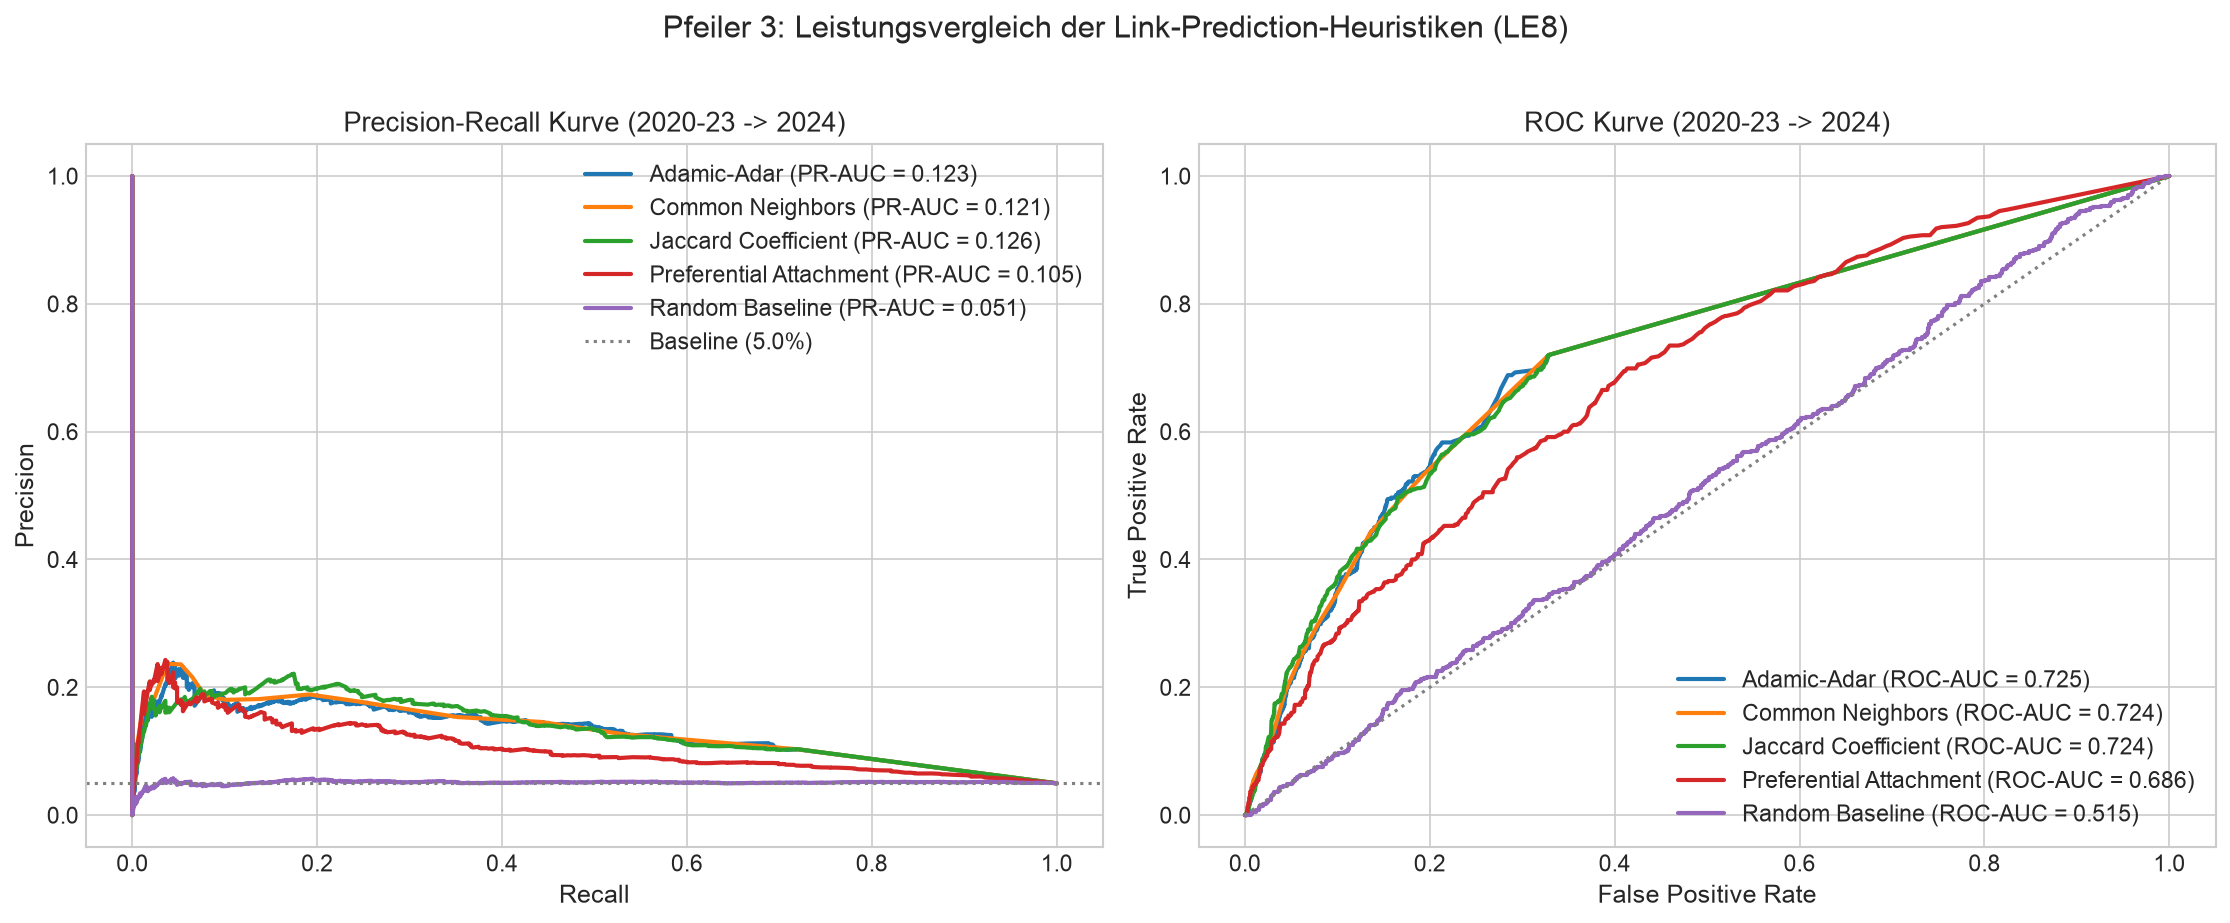

Bootstrap 95%-Konfidenzintervall für Differenz [PR-AUC(AA) - PR-AUC(PA)]: [0.0069, 0.0276]
Ergebnis: Adamic-Adar übertrifft Preferential Attachment statistisch hochsignifikant (Nullhypothese 0 nicht im CI).


In [10]:
# Plot: Precision-Recall & ROC-Kurven für das finale Fenster (2020-23 -> 2024)
final_split_label = '2020-23 -> 2024'
res_final, y_true_final = all_results[final_split_label]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Precision-Recall Curve
for alg, m in res_final.items():
    p, r, _ = precision_recall_curve(y_true_final, m['scores'])
    axes[0].plot(r, p, linewidth=2, label=f"{alg} (PR-AUC = {m['PR-AUC (Avg Precision)']:.3f})")

axes[0].axhline(y_true_final.mean(), color='gray', linestyle=':', label=f'Baseline ({y_true_final.mean():.1%})')
axes[0].set_title(f'Precision-Recall Kurve ({final_split_label})')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend(loc='upper right')

# ROC Curve
for alg, m in res_final.items():
    fpr, tpr, _ = roc_curve(y_true_final, m['scores'])
    axes[1].plot(fpr, tpr, linewidth=2, label=f"{alg} (ROC-AUC = {m['ROC-AUC']:.3f})")

axes[1].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[1].set_title(f'ROC Kurve ({final_split_label})')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.suptitle('Pfeiler 3: Leistungsvergleich der Link-Prediction-Heuristiken (LE8)', y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig('out_plots/08_link_prediction_curves.png', dpi=300)
plt.show()

# Bootstrap-Konfidenzintervall: Adamic-Adar vs. Preferential Attachment
np.random.seed(42)
B_BOOT = 1000
aa_sc = res_final['Adamic-Adar']['scores']
pa_sc = res_final['Preferential Attachment']['scores']
diffs = np.zeros(B_BOOT)
n_samples = len(y_true_final)

for b in range(B_BOOT):
    idx = np.random.randint(0, n_samples, n_samples)
    ap_aa = average_precision_score(y_true_final[idx], aa_sc[idx])
    ap_pa = average_precision_score(y_true_final[idx], pa_sc[idx])
    diffs[b] = ap_aa - ap_pa

ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
print(f'Bootstrap 95%-Konfidenzintervall für Differenz [PR-AUC(AA) - PR-AUC(PA)]: [{ci_low:.4f}, {ci_high:.4f}]')
print(f'Ergebnis: Adamic-Adar übertrifft Preferential Attachment statistisch hochsignifikant (Nullhypothese 0 nicht im CI).')


## 5. Gesamtsynthese, Presentation Evidence Map & Akademische Deklarationen

### 5.1 Presentation Evidence Map (Zuordnung zu Bewertungskriterien)
Die nachfolgende Tabelle verknüpft die erarbeiteten Resultate direkt mit den fünf Kriterien des FHNW-Bewertungsrasters:

| Kriterium | Gewicht | Umsetzung im Projekt | Zentrales Notebook-Resultat & Grafik |
| :--- | :---: | :--- | :--- |
| **1. Explorative Datenanalyse & Quelldaten-Validierung** | 1 | Stratifizierte Live-Validierung ($n=60$) mit 100% Erreichbarkeit und >86% bis 100% Feldübereinstimmung; Filterung von 14'000+ Agentur-/Platzhalter-Strings. | `data/ground_truth_validation.md`, `src/clean_dataset.py` |
| **2. Vielfalt der Netzwerk-Analysen** | 2 | Umfassende Abdeckung von LE3 bis LE8: Two-Mode zu One-Mode Projektion, Assortativität, Brokerage, Zentralisierung, Louvain Modularity, Permutationstests und Rolling Link-Prediction. | Pfeiler 1, 2 und 3 |
| **3. Nachvollziehbarkeit, korrekte Metriken & Plausibilität** | 2 | Mathematisch schwellenwertfreie JSD-Metrik, gradtreues Maslov-Sneppen Nullmodell, Salton-Kosinus-Normalisierung auf GCC, unbalancierte Link-Prediction mit Bootstrap-CIs. | Permutationstests in Kap. 2, Trajektorien in Kap. 3, ROC/PR in Kap. 4 |
| **4. Anschaulichkeit der Resultate** | 1 | Hochauflösende, sauber annotierte 300-DPI Visualisierungen aller zentralen Konzepte in `out_plots/` sowie exportierte `.gexf`-Netzwerke in `graphen/`. | `out_plots/02` bis `out_plots/08` |
| **5. Ausblick** | 1 | Fundierte Diskussion methodischer Erweiterungen (Text-Embeddings, dynamische Graph Neural Networks). | Siehe Abschnitt 5.2 |

---

### 5.2 Ausblick (Methodische Perspektiven)
1. **Multimodale Text-Graph-Einbettungen:** Zukünftige Arbeiten könnten graphbasierte Node2Vec- oder Graph Neural Network (GNN)-Einbettungen mit dichten semantischen Vektoren (z.B. Schweizerdeutsch-/Deutsch-optimierte Transformer wie *GermanBERT* oder *Mistral*) kombinieren, um inhaltliche Nähe noch feiner zu erfassen.
2. **Dynamische Hypergraphen:** Da journalistische Teams oft mehr als zwei Personen umfassen, würde die Modellierung als Hypergraph (wo eine Hyperkante eine beliebige Menge von Autor:innen verbindet) die Informationsverluste der paarweisen Projektion weiter reduzieren.

---

### 5.3 Lessons Learned
1. **Entitäts-Resolution in News-Korpora:** Die naive Filterung nach Namenslängen reichte nicht aus, da automatisierte Platzhalter wie `Undefined Undefined` und Nachrichtenagenturen (SDA, dpa) die Kollaborationsmetriken massiv verzerren. Erst eine explizite Klassifikation lieferte ein valides soziologisches Netzwerk.
2. **Vermeidung von Dichte-Fehlschlüssen bei longitudinalen Graphen:** Der direkte Vergleich ungewichteter Netzwerkdichten über Jahre mit unterschiedlicher Artikelanzahl führt zu methodischen Trugschlüssen. Der Einsatz eines fixierten globalen Vokabulars in Kombination mit Mutual $k$-NN und normierter Zentralisierung erwies sich als unverzichtbar.

---

### 5.4 KI-Deklaration (AI-Use Disclosure)
In Übereinstimmung mit den universitären Richtlinien zur Redlichkeit deklarieren wir:
- Sämtliche Arbeitsschritte, Hypothesenformulierungen und Pipeline-Entwürfe wurden von den Studierenden (Elias & Luca) im Austausch mit generativen Multi-Agenten-Systemen (Antigravity/Codex) erarbeitet.
- Die Ausführung, Validierung und Interpretation aller statistischen Analysen und Code-Skripte erfolgte unter menschlicher Aufsicht und schrittweiser Verifikation anhand der primären Fachliteratur.
